In [ ]:
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import seaborn as sns
from IPython.display import display

print("¡Todo listo!")
print("Versión de Scikit-Learn:", sklearn.__version__)

In [ ]:
# --- Carga de datos ---
from sklearn.datasets import load_breast_cancer

# Cargamos los datos
data = load_breast_cancer(as_frame=True)
X = data.data.copy()
y = data.target.copy()

print("Forma de los datos (filas, columnas):", X.shape)
print("Clases disponibles:", data.target_names)
print("Conteo de clases (0 = maligno, 1 = benigno):")
print(y.value_counts())

In [ ]:
# --- Revisión inicial ---
print("=== Primeras 5 filas de los datos ===")
display(X.head())

print("\n=== ¿Hay datos faltantes? ===")
print("Total de nulos:", X.isna().sum().sum())

In [5]:
import pandas as pd

# 1. Nombres de las columnas
columnas = ['ID', 'Diagnostico']
caracteristicas = [
    'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
    'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se',
    'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst'
]
columnas = columnas + caracteristicas

# 2. Leemos el archivo usando la ruta correcta
df = pd.read_csv('../data/wdbc.data', header=None, names=columnas)

# 3. Convertimos la clase (M = Maligno = 0, B = Benigno = 1)
df['Diagnostico'] = df['Diagnostico'].map({'M': 0, 'B': 1})

# 4. Separamos X y y
X = df.drop(columns=['ID', 'Diagnostico'])
y = df['Diagnostico']

print("¡Datos cargados desde UCI con éxito!")
print("Forma de X:", X.shape)
print("Clases (0=Maligno, 1=Benigno):", y.value_counts().to_dict())
display(X.head())

¡Datos cargados desde UCI con éxito!
Forma de X: (569, 30)
Clases (0=Maligno, 1=Benigno): {1: 357, 0: 212}


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Dividimos los datos (80% para entrenar, 20% para probar)
# El stratify=y asegura que la proporción de benignos/malignos se mantenga igual en ambos grupos.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Entrenamiento: {X_train.shape[0]} muestras")
print(f"Prueba: {X_test.shape[0]} muestras")

# 2. Escalado de datos (Obligatorio para SVM y Redes Neuronales)
# Ajustamos el escalador SOLO con los datos de entrenamiento para no filtrar información.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("¡Datos divididos y escalados con éxito!")

Entrenamiento: 455 muestras
Prueba: 114 muestras
¡Datos divididos y escalados con éxito!


In [7]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Creamos y entrenamos el modelo
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

# 2. Hacemos las predicciones con los datos de prueba
y_pred_nb = nb_model.predict(X_test_scaled)
y_prob_nb = nb_model.predict_proba(X_test_scaled)[:, 1] # Probabilidades para ROC

# 3. Calculamos las métricas que pide el profe
print("=== RESULTADOS NAIVE BAYES ===")
print(f"Exactitud (Accuracy): {accuracy_score(y_test, y_pred_nb):.4f}")
print(f"Precisión: {precision_score(y_test, y_pred_nb):.4f}")
print(f"Sensibilidad (Recall): {recall_score(y_test, y_pred_nb):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_nb):.4f}")
print(f"AUC-ROC: {roc_auc_score(y_test, y_prob_nb):.4f}")

=== RESULTADOS NAIVE BAYES ===
Exactitud (Accuracy): 0.9298
Precisión: 0.9444
Sensibilidad (Recall): 0.9444
F1-Score: 0.9444
AUC-ROC: 0.9868


In [8]:
from sklearn.linear_model import LogisticRegression

# 1. Creamos y entrenamos el modelo
# max_iter=1000 es para asegurar que tenga tiempo de converger (encontrar la mejor solución)
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

# 2. Predicciones
y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# 3. Métricas
print("=== RESULTADOS REGRESIÓN LOGÍSTICA (BASELINE) ===")
print(f"Exactitud (Accuracy): {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precisión: {precision_score(y_test, y_pred_lr):.4f}")
print(f"Sensibilidad (Recall): {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_lr):.4f}")
print(f"AUC-ROC: {roc_auc_score(y_test, y_prob_lr):.4f}")


=== RESULTADOS REGRESIÓN LOGÍSTICA (BASELINE) ===
Exactitud (Accuracy): 0.9825
Precisión: 0.9861
Sensibilidad (Recall): 0.9861
F1-Score: 0.9861
AUC-ROC: 0.9954


In [10]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

# 1. Definimos los parámetros que queremos probar
parametros_svm = [
    {'kernel': ['linear'], 'C': [0.1, 1, 10, 100]},
    {'kernel': ['rbf'], 'C': [0.1, 1, 10, 100], 'gamma': [0.001, 0.01, 0.1, 1]}
]

# 2. Configuramos la búsqueda con validación cruzada de 5 pliegues
svm_grid = GridSearchCV(SVC(probability=True, random_state=42), 
                        parametros_svm, 
                        cv=5, 
                        scoring='accuracy', 
                        n_jobs=-1)

# 3. Entrenamos
svm_grid.fit(X_train_scaled, y_train)

# 4. Vemos cuál fue la mejor combinación
print("=== MEJOR CONFIGURACIÓN SVM ===")
print("Mejores parámetros:", svm_grid.best_params_)
print(f"Mejor exactitud en validación cruzada: {svm_grid.best_score_:.4f}\n")

# 5. Evaluamos el mejor modelo en el conjunto de prueba
best_svm = svm_grid.best_estimator_
y_pred_svm = best_svm.predict(X_test_scaled)
y_prob_svm = best_svm.predict_proba(X_test_scaled)[:, 1]

print("=== RESULTADOS SVM (Conjunto de Prueba) ===")
print(f"Exactitud (Accuracy): {accuracy_score(y_test, y_pred_svm):.4f}")
print(f"Precisión: {precision_score(y_test, y_pred_svm):.4f}")
print(f"Sensibilidad (Recall): {recall_score(y_test, y_pred_svm):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_svm):.4f}")
print(f"AUC-ROC: {roc_auc_score(y_test, y_prob_svm):.4f}")

c:\Users\joann\OneDrive\Escritorio\poyecto\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


=== MEJOR CONFIGURACIÓN SVM ===
Mejores parámetros: {'C': 0.1, 'kernel': 'linear'}
Mejor exactitud en validación cruzada: 0.9802

=== RESULTADOS SVM (Conjunto de Prueba) ===
Exactitud (Accuracy): 0.9825
Precisión: 0.9861
Sensibilidad (Recall): 0.9861
F1-Score: 0.9861
AUC-ROC: 0.9937


In [11]:
from sklearn.neural_network import MLPClassifier

# 1. Creamos la Red Neuronal
# Usamos max_iter=1000 para darle tiempo de entrenar, y early_stopping=True para que pare si empieza a fallar
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32), # Dos capas ocultas
    activation='relu',           # Función de activación estándar
    solver='adam',               # Optimizador moderno
    alpha=0.01,                  # Regularización L2 (evita sobreajuste)
    early_stopping=True,         # Detención temprana
    random_state=42,             # Semilla para reproducibilidad
    max_iter=1000
)

# 2. Entrenamos
mlp_model.fit(X_train_scaled, y_train)

# 3. Predicciones
y_pred_mlp = mlp_model.predict(X_test_scaled)
y_prob_mlp = mlp_model.predict_proba(X_test_scaled)[:, 1]

# 4. Métricas
print("=== RESULTADOS RED NEURONAL (MLP) ===")
print(f"Exactitud (Accuracy): {accuracy_score(y_test, y_pred_mlp):.4f}")
print(f"Precisión: {precision_score(y_test, y_pred_mlp):.4f}")
print(f"Sensibilidad (Recall): {recall_score(y_test, y_pred_mlp):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_mlp):.4f}")
print(f"AUC-ROC: {roc_auc_score(y_test, y_prob_mlp):.4f}")

=== RESULTADOS RED NEURONAL (MLP) ===
Exactitud (Accuracy): 0.9474
Precisión: 0.9459
Sensibilidad (Recall): 0.9722
F1-Score: 0.9589
AUC-ROC: 0.9927


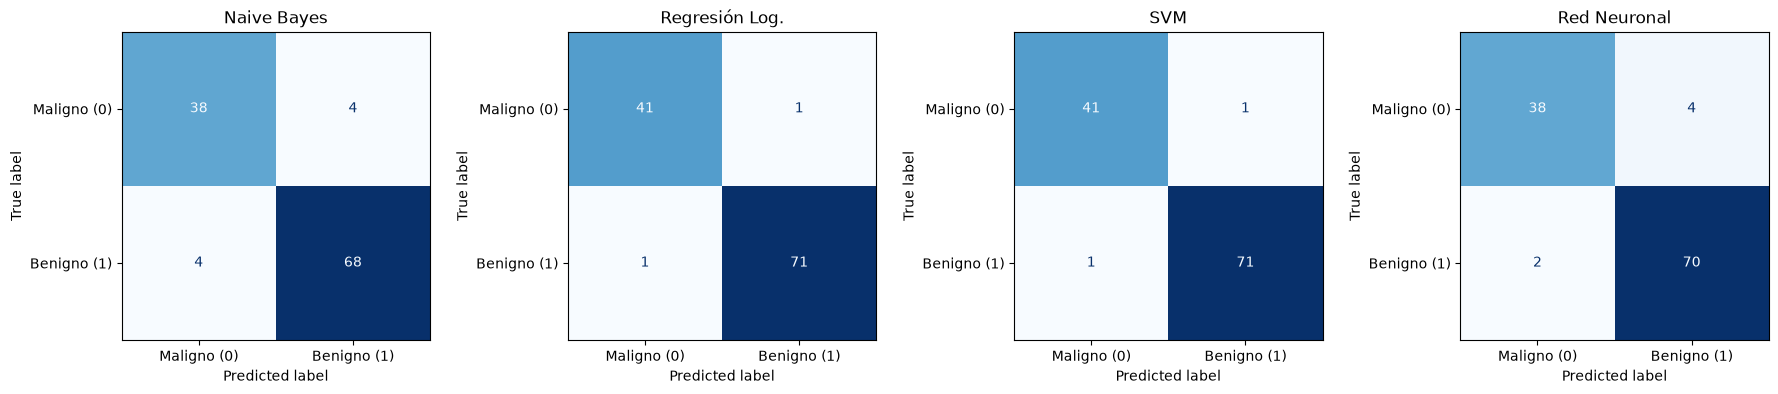

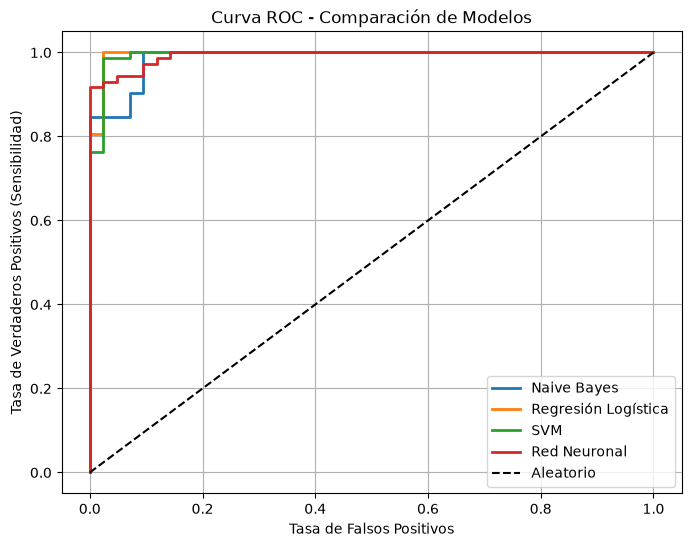

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve

# --- 1. Gráfico de Matrices de Confusión ---
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
modelos = ['Naive Bayes', 'Regresión Log.', 'SVM', 'Red Neuronal']
predicciones = [y_pred_nb, y_pred_lr, y_pred_svm, y_pred_mlp]

for ax, nombre, pred in zip(axes, modelos, predicciones):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Maligno (0)', 'Benigno (1)'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(nombre)

plt.tight_layout()
plt.savefig('../results/figures/matrices_confusion.png', dpi=150)
plt.show()

# --- 2. Curva ROC Comparativa ---
plt.figure(figsize=(8, 6))

plt.plot(*roc_curve(y_test, y_prob_nb)[:2], label='Naive Bayes', linewidth=2)
plt.plot(*roc_curve(y_test, y_prob_lr)[:2], label='Regresión Logística', linewidth=2)
plt.plot(*roc_curve(y_test, y_prob_svm)[:2], label='SVM', linewidth=2)
plt.plot(*roc_curve(y_test, y_prob_mlp)[:2], label='Red Neuronal', linewidth=2)

# Línea diagonal (modelo aleatorio)
plt.plot([0, 1], [0, 1], 'k--', label='Aleatorio')

plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
plt.title('Curva ROC - Comparación de Modelos')
plt.legend(loc='lower right')
plt.grid(True)
plt.savefig('../results/figures/curva_roc.png', dpi=150)
plt.show()

In [13]:
import pandas as pd

# Creamos un diccionario con los resultados que ya obtuvimos
resultados = {
    'Modelo': ['Naive Bayes', 'Regresión Log.', 'SVM', 'Red Neuronal'],
    'Accuracy': [0.9298, 0.9825, 0.9825, 0.9474],
    'Precisión': [0.9444, 0.9861, 0.9861, 0.9459],
    'Recall': [0.9444, 0.9861, 0.9861, 0.9722],
    'F1-Score': [0.9444, 0.9861, 0.9861, 0.9589],
    'AUC-ROC': [0.9868, 0.9954, 0.9937, 0.9927]
}

df_resultados = pd.DataFrame(resultados)
print("=== TABLA COMPARATIVA FINAL ===")
display(df_resultados)

=== TABLA COMPARATIVA FINAL ===


,Modelo,Accuracy,Precisión,Recall,F1-Score,AUC-ROC
0,Naive Bayes,0.9298,0.9444,0.9444,0.9444,0.9868
1,Regresión Log.,0.9825,0.9861,0.9861,0.9861,0.9954
2,SVM,0.9825,0.9861,0.9861,0.9861,0.9937
3,Red Neuronal,0.9474,0.9459,0.9722,0.9589,0.9927


In [14]:
from sklearn.model_selection import cross_val_score

print("=== VARIABILIDAD DE LOS MODELOS (Validación Cruzada 10-Folds) ===")
print("(Evaluando sobre todo el conjunto de datos escalado)\n")

# Escalamos TODO el dataset para la validación cruzada (es una práctica estándar en este paso)
X_scaled_all = scaler.fit_transform(X)

# Lista de los modelos que ya entrenamos
modelos_cv = {
    "Naive Bayes": GaussianNB(),
    "Regresión Log.": LogisticRegression(random_state=42, max_iter=1000),
    "SVM (Lineal)": SVC(kernel='linear', C=0.1, random_state=42),
    "Red Neuronal": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=42)
}

for nombre, modelo in modelos_cv.items():
    # Hacemos la validación cruzada (cv=10)
    scores = cross_val_score(modelo, X_scaled_all, y, cv=10, scoring='accuracy')
    
    # Calculamos media y desviación estándar
    media = scores.mean()
    std = scores.std()
    
    print(f"{nombre:15} | Exactitud Media: {media:.4f} | Desviación Estándar: +/- {std:.4f}")

=== VARIABILIDAD DE LOS MODELOS (Validación Cruzada 10-Folds) ===
(Evaluando sobre todo el conjunto de datos escalado)

Naive Bayes     | Exactitud Media: 0.9315 | Desviación Estándar: +/- 0.0327
Regresión Log.  | Exactitud Media: 0.9807 | Desviación Estándar: +/- 0.0146
SVM (Lineal)    | Exactitud Media: 0.9789 | Desviación Estándar: +/- 0.0205
Red Neuronal    | Exactitud Media: 0.9772 | Desviación Estándar: +/- 0.0158


In [15]:
import pandas as pd

# 1. Encontramos los índices donde el modelo se equivocó
# (Comparamos la respuesta real y_test con la predicción y_pred_lr)
errores = (y_test != y_pred_lr)
indices_error = y_test[errores].index

print(f"El modelo de Regresión Logística falló en {len(indices_error)} casos.")
print("Índices de los pacientes en el dataset original:", list(indices_error))

# 2. Veamos los datos de esos pacientes para analizarlos
if len(indices_error) > 0:
    print("\n=== DATOS DE LOS PACIENTES MAL CLASIFICADOS ===")
    # Seleccionamos solo algunas variables clave para no saturar la pantalla
    variables_clave = ['radius_mean', 'texture_mean', 'concavity_mean', 'symmetry_mean']
    
    # Mostramos sus datos y qué clase era realmente
    df_errores = X.loc[indices_error, variables_clave].copy()
    df_errores['Clase Real (0=Mal, 1=Ben)'] = y.loc[indices_error]
    df_errores['Predicción del Modelo'] = y_pred_lr[errores]
    
    display(df_errores)

El modelo de Regresión Logística falló en 2 casos.
Índices de los pacientes en el dataset original: [541, 73]

=== DATOS DE LOS PACIENTES MAL CLASIFICADOS ===


,radius_mean,texture_mean,concavity_mean,symmetry_mean,"Clase Real (0=Mal, 1=Ben)",Predicción del Modelo
541,14.47,24.99,0.10090,0.1872,1,0
73,13.80,15.79,0.07789,0.1662,0,1


C:\Users\joann\AppData\Local\Temp\ipykernel_18116\1598943786.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y.map({0: 'Maligno', 1: 'Benigno'}), palette='Set2')


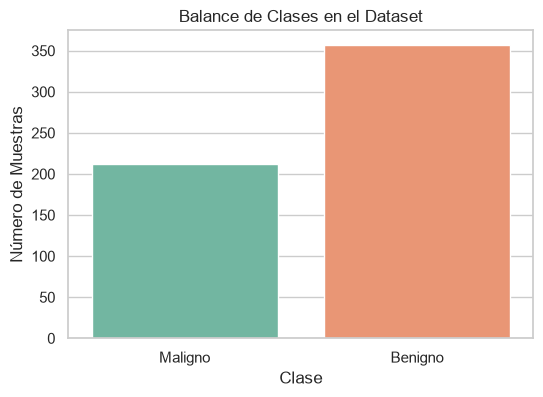

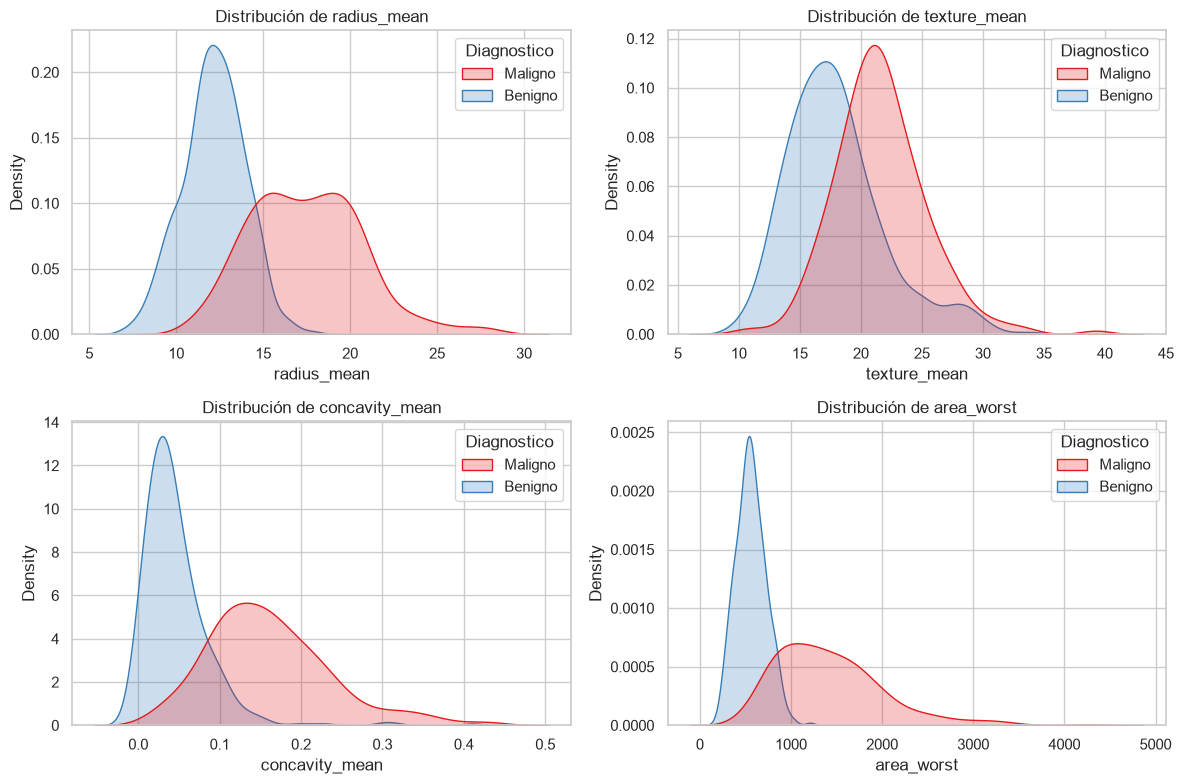

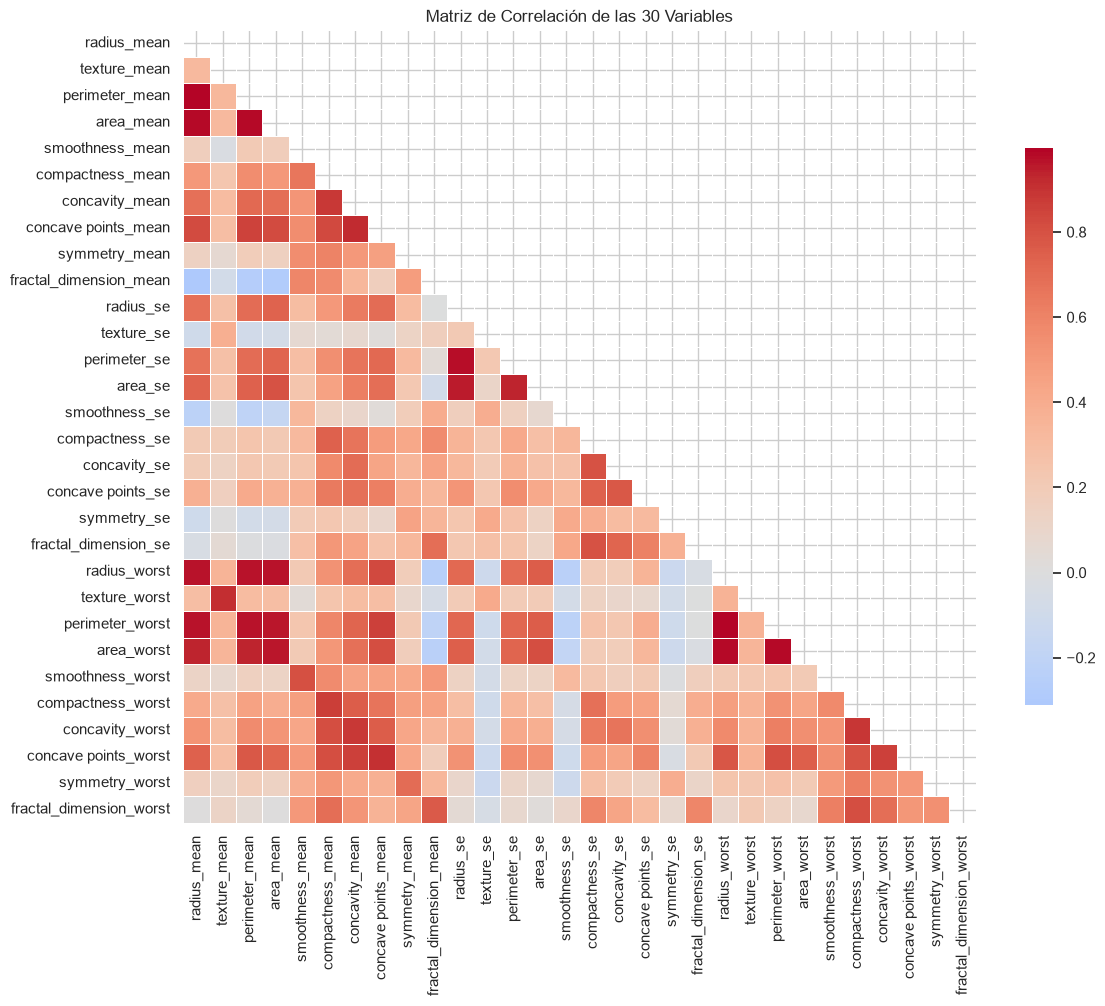

¡Las 3 gráficas se han guardado en la carpeta 'results/figures'!


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Aseguramos que las gráficas se vean bonitas
sns.set_theme(style="whitegrid")

# ==========================================
# GRÁFICA 1: BALANCE DE CLASES
# ==========================================
plt.figure(figsize=(6, 4))
sns.countplot(x=y.map({0: 'Maligno', 1: 'Benigno'}), palette='Set2')
plt.title('Balance de Clases en el Dataset')
plt.xlabel('Clase')
plt.ylabel('Número de Muestras')
plt.savefig('../results/figures/fig1_balance.png', dpi=150, bbox_inches='tight')
plt.show()

# ==========================================
# GRÁFICA 2: DISTRIBUCIONES DE VARIABLES CLAVE
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
features = ['radius_mean', 'texture_mean', 'concavity_mean', 'area_worst']

for ax, feat in zip(axes.ravel(), features):
    sns.kdeplot(data=X, x=feat, hue=y.map({0: 'Maligno', 1: 'Benigno'}),
                fill=True, common_norm=False, ax=ax, palette='Set1')
    ax.set_title(f'Distribución de {feat}')
    ax.set_xlabel(feat)
    
plt.tight_layout()
plt.savefig('../results/figures/fig2_distribuciones.png', dpi=150, bbox_inches='tight')
plt.show()

# ==========================================
# GRÁFICA 3: MATRIZ DE CORRELACIÓN
# ==========================================
plt.figure(figsize=(12, 10))
corr = X.corr()
mask = np.triu(np.ones_like(corr, dtype=bool)) # Para que sea un triángulo
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, square=True,
            cbar_kws={'shrink': .7}, linewidths=.5)
plt.title('Matriz de Correlación de las 30 Variables')
plt.tight_layout()
plt.savefig('../results/figures/fig3_correlacion.png', dpi=150, bbox_inches='tight')
plt.show()

print("¡Las 3 gráficas se han guardado en la carpeta 'results/figures'!")

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8, 6))

# Calculamos y graficamos para el SVM (nuestro mejor modelo)
precision, recall, _ = precision_recall_curve(y_test, y_prob_svm)
ap_score = average_precision_score(y_test, y_prob_svm)

plt.plot(recall, precision, label=f'SVM (AP = {ap_score:.4f})', color='green', linewidth=2)

plt.xlabel('Sensibilidad (Recall)')
plt.ylabel('Precisión')
plt.title('Curva Precisión-Recall (SVM)')
plt.legend(loc='lower left')
plt.grid(True)
plt.savefig('../results/figures/curva_pr.png', dpi=150, bbox_inches='tight')
plt.show()